In [1]:
import time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf
from pathlib import Path
import kagglehub
from kagglehub import KaggleDatasetAdapter
import urllib.request

C:\Users\Admin\AppData\Local\anaconda3\envs\ml-projects\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (12, 4)
sns.set_style("whitegrid")
torch.set_num_threads(max(1, torch.get_num_threads()))

In [3]:
from pathlib import Path

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

In [4]:
H_MAX, N_SEG = 14, 10
HORIZONS = [1, 7, 14]
SEED = 42

# Загрузка данных

Нейросетям нужно больше данных чем AR моделям, поэтому перед тестовой зоной возьмем всю доступную историю

акции Apple

In [5]:
df_apple = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "anukaggle81/usa-top-900-historic-dataset",
    "Apple.csv",
)
df_apple = df_apple.drop(columns=["Unnamed: 0"])
df_apple["Date"] = pd.to_datetime(df_apple["Date"])
df_apple = df_apple.sort_values("Date").reset_index(drop=True)

apple = df_apple["Close"].to_numpy(dtype=float)
print("Apple:", apple.shape)

Apple: (11156,)


MTA Subway Hourly Ridership (NYC)

In [6]:
url = "https://github.com/xinychen/integers/raw/main/Manhattan-subway/NYC_subway_mob_24.npz"
urllib.request.urlretrieve(url, DATA_DIR / "NYC_subway_mob_24.npz")
tensor = np.load(DATA_DIR / "NYC_subway_mob_24.npz")["arr_0"]
hourly_total = tensor.sum(axis=0)

dates_sub = pd.date_range("2024-01-01", periods=len(hourly_total), freq="h")
subway = hourly_total[: dates_sub.get_loc("2024-10-30 23:00") + 1].astype(float)

bad = np.where(subway == 0)[0]
subway[bad] = (subway[bad - 1] + subway[bad + 1]) / 2
print("Subway:", subway.shape, "заменены нули:", list(dates_sub[bad]))

Subway: (7296,) заменены нули: [Timestamp('2024-03-10 02:00:00')]


Решила взять другой датасет вместо ЭКГ

PJM Hourly Energy Consumption Data

In [7]:
energy_path = kagglehub.dataset_download("robikscube/hourly-energy-consumption")
df_energy = pd.read_csv(Path(energy_path) / "PJME_hourly.csv")
df_energy["Datetime"] = pd.to_datetime(df_energy["Datetime"])
df_energy = (df_energy.drop_duplicates(subset="Datetime")
                      .sort_values("Datetime")
                      .set_index("Datetime"))

g = df_energy["PJME_MW"].resample("D")
daily = g.mean()[g.count() >= 23]
energy = daily.to_numpy(dtype=float)
print("Energy:", energy.shape, daily.index[0].date(), "—", daily.index[-1].date())

Energy: (6058,) 2002-01-01 — 2018-08-02


In [8]:
SERIES = {"Apple": apple, "Subway": subway, "Energy": energy}
UNIT = {"Apple": "торг. дни", "Subway": "ч", "Energy": "сут"}

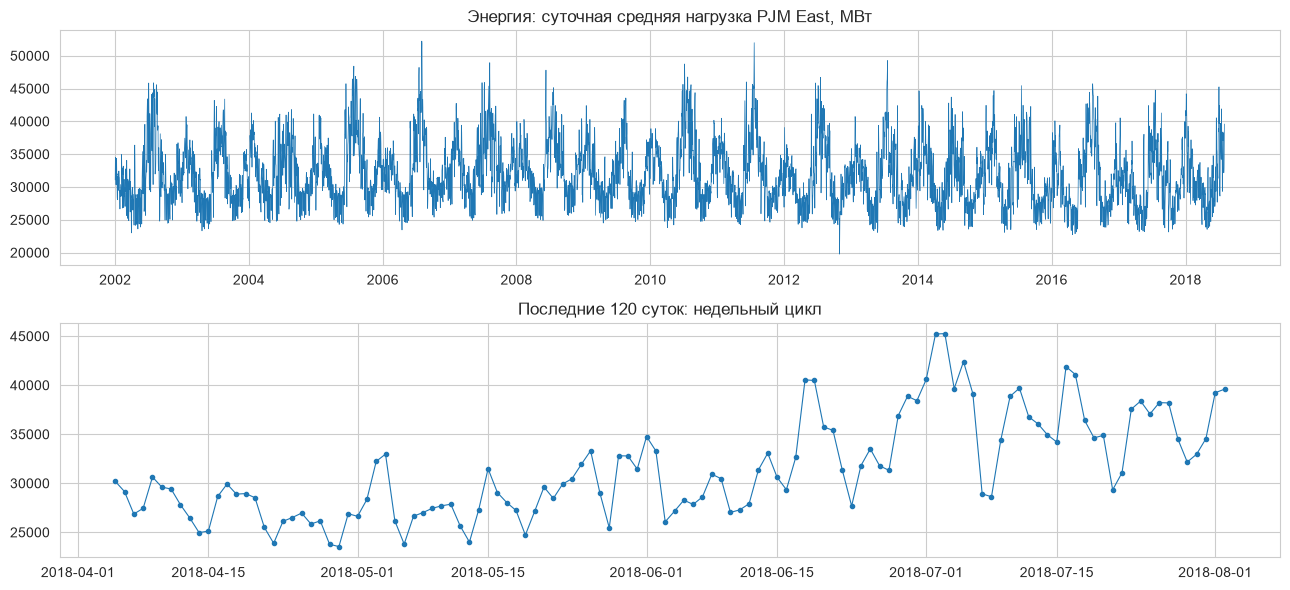

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6))
axes[0].plot(daily.index, energy, lw=0.5)
axes[0].set_title("Энергия: суточная средняя нагрузка PJM East, МВт")
axes[1].plot(daily.index[-120:], energy[-120:], ".-", lw=0.8)
axes[1].set_title("Последние 120 суток: недельный цикл")
plt.tight_layout(); plt.show()

На всем ряде виден годовой цикл с двумя пиками зимний с отоплением, летний более высокий - использование кондиционеров, и минимумами весной и осенью

# Тестовые блоки

Функция test_origins та же, что в работе 2: 10 блоков по 14 шагов подряд в конце ряда. Для энергии это 140 суток: с 16 марта по 2 августа 2018 года, то есть переход от весеннего минимума к летнему пику

Для обучения нейросетей используется вся история до начала первого тестового блока: последние 15% окон этой истории идут на валидацию, остальные на обучение

Энергия, тестовая зона: 2018-03-16 — 2018-08-02


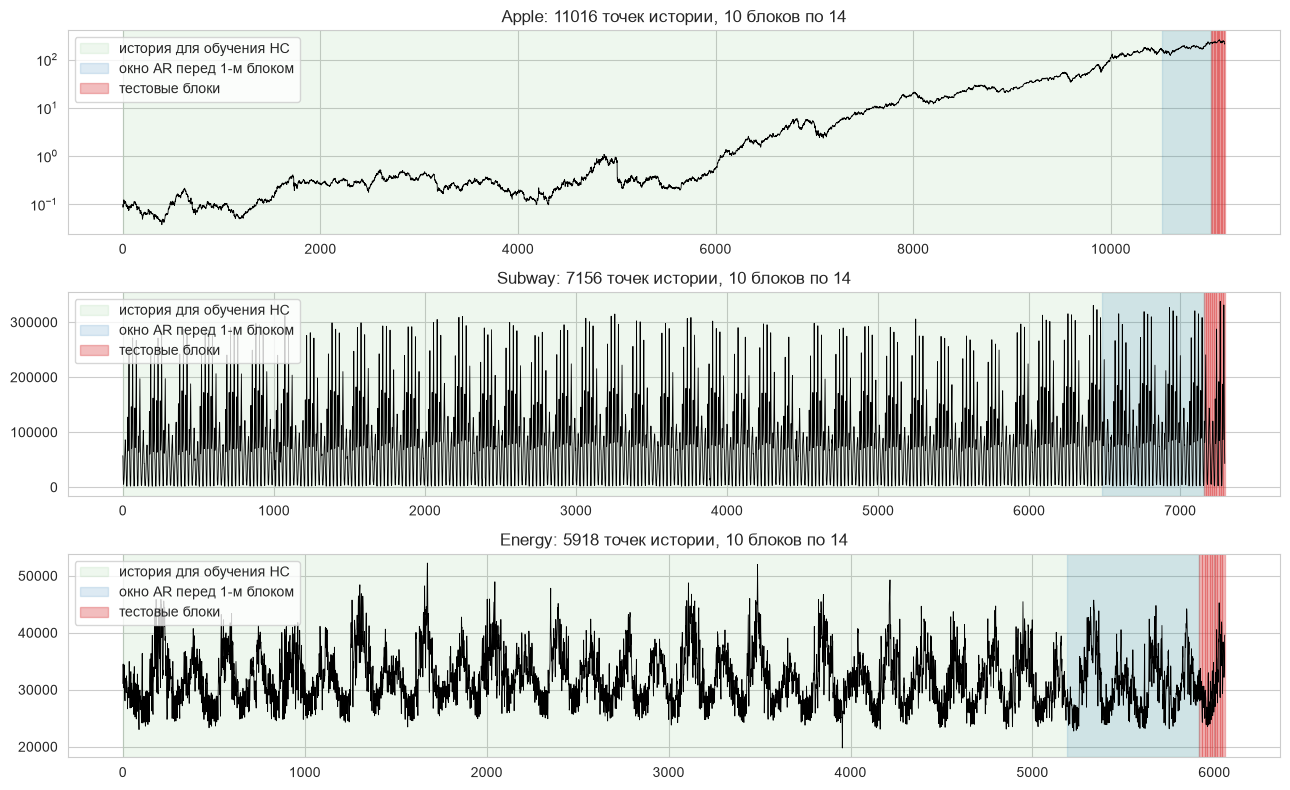

In [10]:
GAP = {"Apple": H_MAX, "Subway": H_MAX, "Energy": H_MAX}
TRAIN_LEN_AR = {"Apple": 500, "Subway": 24 * 7 * 4, "Energy": 730}

def test_origins(n, n_seg=N_SEG, h=H_MAX, gap=H_MAX):
    assert gap >= h, "блоки не должны пересекаться"
    return [n - h - gap * (n_seg - 1 - k) for k in range(n_seg)]

ORIGINS = {name: test_origins(len(x), gap=GAP[name]) for name, x in SERIES.items()}
print("Энергия, тестовая зона:", daily.index[ORIGINS["Energy"][0]].date(), "—", daily.index[-1].date())

fig, axes = plt.subplots(3, 1, figsize=(13, 8))
for ax, (name, x) in zip(axes, SERIES.items()):
    o = ORIGINS[name]
    ax.plot(x, lw=0.6, color="black")
    if name == "Apple":
        ax.set_yscale("log")   # Цена росла экспоненциально, в линейной шкале первые 30 лет сливаются с нулем
    ax.axvspan(0, o[0], color="tab:green", alpha=0.08, label="история для обучения НС")
    ax.axvspan(o[0] - TRAIN_LEN_AR[name], o[0], color="tab:blue", alpha=0.15, label="окно AR перед 1-м блоком")
    for k, s in enumerate(o):
        ax.axvspan(s, s + H_MAX, color="tab:red", alpha=0.3, label="тестовые блоки" if k == 0 else None)
    ax.set_title(f"{name}: {o[0]} точек истории, 10 блоков по {H_MAX}")
    ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

# Метрики

In [11]:
def mape(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return np.mean(np.abs((y - yhat) / y)) * 100

def mae(y, yhat):
    return np.mean(np.abs(np.asarray(y, float) - np.asarray(yhat, float)))

# Авторегрессионные модели

Для Apple и метро конфигурации из работы 2

Для энергии подбор тем же способом, что в работе 2

Окно подбора 2 года (730 суток) перед первым тестовым блоком, на таком же окне модели потом переобучаются перед каждым блоком. Окно включает два годовых цикла, но SARIMA на нем подгоняется за секунды.
* choose_d — порядок дифференцирования по связке ADF (H0: единичный корень) и KPSS (H0: стационарность);
* AR — порядок по BIC (ar_select_order, лаги до 30);
* ARIMA — p, q ∈ {0…3} по AIC;
* SARIMA — недельный период m = 7, D = 1, p, q ∈ {0, 1, 2}, P, Q ∈ {0, 1} по AIC. Годовой период m = 365 в SARIMA не берем: state-space модель с 365 состояниями на 730 точках не оценить;
* Хольт–Винтерс — m = 7, аддитивная или мультипликативная сезонность, без тренда или с затухающим трендом, по AICc;
* наивный прогноз — копия прошлой недели (m = 7).

In [12]:
def choose_d(x, max_d=2, alpha=0.05, seasonal_lag=None):
    z = np.asarray(x, float)
    if seasonal_lag:
        z = z[seasonal_lag:] - z[:-seasonal_lag]
    rows = []
    for d in range(max_d + 1):
        zd = np.diff(z, n=d) if d else z
        adf_p = adfuller(zd, autolag="AIC")[1]
        kpss_p = kpss(zd, regression="c", nlags="auto")[1]
        rows.append({"d": d, "ADF p-value": round(adf_p, 4), "KPSS p-value": round(kpss_p, 4)})
        if adf_p < alpha and kpss_p > alpha:
            return d, pd.DataFrame(rows)
    return max_d, pd.DataFrame(rows)


def grid_sarima(x, d, p_range, q_range, P_range=(0,), Q_range=(0,), D=0, m=0):
    trend = "c" if (d + D) == 0 else "n"
    rows = []
    for p in p_range:
        for q in q_range:
            for P in P_range:
                for Q in Q_range:
                    try:
                        res = SARIMAX(x, order=(p, d, q), seasonal_order=(P, D, Q, m) if m else (0, 0, 0, 0),
                                      trend=trend).fit(disp=False)
                        rows.append({"p": p, "d": d, "q": q, "P": P, "D": D, "Q": Q, "AIC": res.aic})
                    except Exception:
                        pass
    return pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)


def grid_hw(x, configs):
    rows = []
    for cfg in configs:
        try:
            res = ExponentialSmoothing(x, initialization_method="estimated", **cfg).fit()
            rows.append({**cfg, "AICc": res.aicc, "alpha": res.params["smoothing_level"],
                         "gamma": res.params.get("smoothing_seasonal")})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values("AICc").reset_index(drop=True)

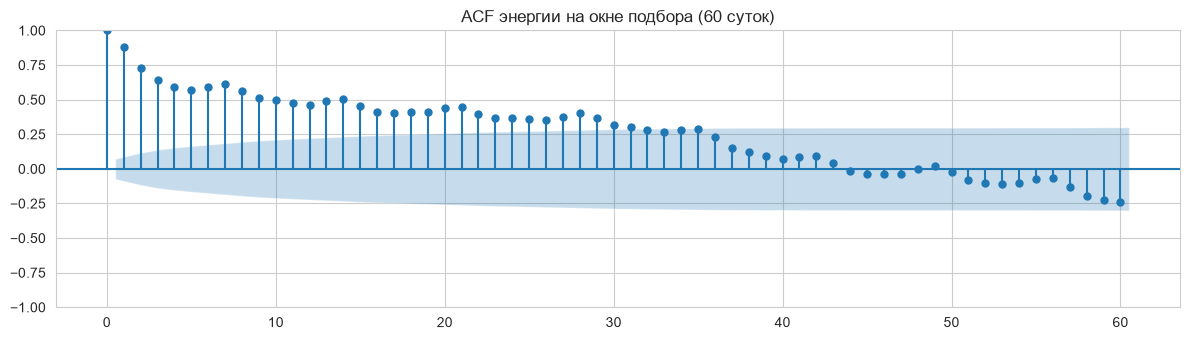

d без сезонной разности: 1


,d,ADF p-value,KPSS p-value
0,0,0.0607,0.1
1,1,0.0000,0.1


d после недельной разности: 0


,d,ADF p-value,KPSS p-value
0,0,0.0,0.1


In [13]:
x_e = SERIES["Energy"]
sel = x_e[ORIGINS["Energy"][0] - TRAIN_LEN_AR["Energy"]: ORIGINS["Energy"][0]]

fig, ax = plt.subplots(figsize=(12, 3.5))
plot_acf(sel, lags=60, ax=ax, title="ACF энергии на окне подбора (60 суток)")
plt.tight_layout(); plt.show()

d_e, tbl = choose_d(sel)
d_e7, tbl7 = choose_d(sel, seasonal_lag=7)
print(f"d без сезонной разности: {d_e}");  display(tbl)
print(f"d после недельной разности: {d_e7}"); display(tbl7)

* ACF на окне подбора убывает медленно, с локальными пиками на лагах 7, 14, 21, 28 (недельный цикл), и к 50 суткам становится отрицательной. Уровень ряда нестационарен
* ADF без дифференцирования p = 0.0607, гипотезу о единичном корне отвергнуть нельзя, поэтому d = 1. После недельной разности ряд стационарен (ADF p = 0, KPSS p = 0.1), поэтому в SARIMA d = 0, D = 1

In [14]:
ar_sel = ar_select_order(sel, maxlag=30, ic="bic", trend="c")
print("Лаги AR по BIC:", ar_sel.ar_lags)

g_arima = grid_sarima(sel, d=d_e, p_range=range(4), q_range=range(4))
display(g_arima.head(3))
order_e = tuple(int(g_arima.loc[0, k]) for k in ("p", "d", "q"))

t0 = time.perf_counter()
g_sar = grid_sarima(sel, d=d_e7, p_range=range(3), q_range=range(3), P_range=(0, 1), Q_range=(0, 1), D=1, m=7)
print(f"сетка SARIMA: {time.perf_counter() - t0:.1f} с")
display(g_sar.head(3))
r0 = g_sar.loc[0]
sorder_e, sseas_e = (int(r0.p), int(r0.d), int(r0.q)), (int(r0.P), 1, int(r0.Q), 7)

hw_cfgs = [dict(trend=t, damped_trend=t is not None, seasonal=s, seasonal_periods=7)
           for t in (None, "add") for s in ("add", "mul")]
g_hw = grid_hw(sel, hw_cfgs)
display(g_hw.round(4))
best_hw = {k: g_hw.loc[0, k] for k in ("trend", "damped_trend", "seasonal", "seasonal_periods")}
best_hw["trend"] = None if pd.isna(best_hw["trend"]) else best_hw["trend"]
best_hw["damped_trend"] = bool(best_hw["damped_trend"]) and best_hw["trend"] is not None
best_hw["seasonal_periods"] = int(best_hw["seasonal_periods"])
print("ARIMA", order_e, "| SARIMA", sorder_e, "x", sseas_e, "| Хольт–Винтерс", best_hw)

Лаги AR по BIC: [1, 2, 3, 4, 5, 6, 7, 8, 9]


,p,d,q,P,D,Q,AIC
0,3,1,3,0,0,0,13246.259717
1,1,1,2,0,0,0,13256.685039
2,2,1,2,0,0,0,13257.917685


сетка SARIMA: 11.8 с


,p,d,q,P,D,Q,AIC
0,2,0,2,0,1,1,13051.577034
1,1,0,2,0,1,1,13063.422125
2,1,0,2,1,1,1,13065.388755


,trend,damped_trend,seasonal,seasonal_periods,AICc,alpha,gamma
0,NaN,False,add,7,11077.0335,1.0,0.0
1,NaN,False,mul,7,11078.9165,1.0,0.0
2,add,True,add,7,11081.8683,1.0,0.0
3,add,True,mul,7,11085.1678,1.0,0.0


ARIMA (3, 1, 3) | SARIMA (2, 0, 2) x (0, 1, 1, 7) | Хольт–Винтерс {'trend': None, 'damped_trend': False, 'seasonal': 'add', 'seasonal_periods': 7}


* AR по BIC: 9 лагов, то есть больше недели, включая лаг 7
* ARIMA(3,1,3) и SARIMA(2,0,2)×(0,1,1,7). У SARIMA сезонная часть, только скользящее среднее после недельной разности
* Хольт–Винтерс: аддитивная недельная сезонность без тренда, α = 1.0, γ = 0.0. Уровень полностью следует за последним наблюдением, а недельный профиль не обновляется, то есть «последнее значение плюс поправка на день недели»

In [15]:
CFG_AR = {
    "Apple": dict(ar_lags=[1], order=(0, 1, 0), arima_trend="n",
                  hw=dict(trend=None, seasonal=None), hw_init="estimated", naive_m=1),
    "Subway": dict(ar_lags=list(range(1, 171)), order=(3, 0, 3), arima_trend="c",
                   sarima_order=(2, 0, 1), sarima_seasonal=(1, 1, 1, 24),
                   hw=dict(trend=None, damped_trend=False, seasonal="mul", seasonal_periods=168),
                   hw_init="estimated", naive_m=24, naive_week_m=168),
    "Energy": dict(ar_lags=ar_sel.ar_lags, order=order_e, arima_trend="c" if d_e == 0 else "n",
                   sarima_order=sorder_e, sarima_seasonal=sseas_e,
                   hw=best_hw, hw_init="estimated", naive_m=7),
}

def fc_ar(tr, c):     return AutoReg(tr, lags=c["ar_lags"], trend="c").fit().predict(len(tr), len(tr) + H_MAX - 1)

REFIT_LOG = []

def fit_forecast_sarimax(tr, **kw):
    """SARIMAX с проверкой: если оптимизатор не сошелся или прогноз вышел далеко за диапазон ряда,
    перезапускаем Нелдером–Мидом (медленнее, но устойчивее) и доуточняем L-BFGS из найденной точки."""
    model = SARIMAX(tr, **kw)
    res = model.fit(disp=False)
    fc = res.forecast(H_MAX)
    bad = (not res.mle_retvals.get("converged", True)
           or fc.min() < 0.5 * tr.min() or fc.max() > 2 * tr.max())
    if bad:
        res = model.fit(disp=False, method="nm", maxiter=3000)
        res = model.fit(disp=False, start_params=res.params)
        fc = res.forecast(H_MAX)
        REFIT_LOG.append(dict(order=kw.get("order"), seasonal=kw.get("seasonal_order"), n=len(tr)))
    return fc

def fc_arima(tr, c):  return fit_forecast_sarimax(tr, order=c["order"], trend=c["arima_trend"])
def fc_sarima(tr, c): return fit_forecast_sarimax(tr, order=c["sarima_order"],
                                                  seasonal_order=c["sarima_seasonal"], trend="n")
def fc_hw(tr, c):     return ExponentialSmoothing(tr, initialization_method=c["hw_init"], **c["hw"]).fit().forecast(H_MAX)
def fc_naive(tr, c, key="naive_m"):
    m = c[key]
    return np.array([tr[len(tr) - m + (i % m)] for i in range(H_MAX)])

AR_MODELS = {"AR": fc_ar, "ARIMA": fc_arima, "SARIMA": fc_sarima, "Holt-Winters": fc_hw,
             "Naive": fc_naive, "Naive-168": lambda tr, c: fc_naive(tr, c, "naive_week_m")}

Naive: последнее значение для Apple, копия прошлых суток для метро (m = 24), копия прошлой недели для энергии (m = 7). Naive-168: копия прошлой недели для метро

Время считается как сумма по 10 блокам: модель заново обучается на окне перед каждым блоком и строит прогноз

In [16]:
rows, timing, forecasts = [], [], {}
for name, x in SERIES.items():
    c = CFG_AR[name]
    for mname, f in AR_MODELS.items():
        if mname == "SARIMA" and "sarima_order" not in c: continue
        if mname == "Naive-168" and "naive_week_m" not in c: continue
        t0 = time.perf_counter()
        for k, o in enumerate(ORIGINS[name]):
            yhat = np.asarray(f(x[o - TRAIN_LEN_AR[name]: o], c), float)
            forecasts[(name, mname, k)] = yhat
            for h in HORIZONS:
                rows.append(dict(series=name, model=mname, family="AR", horizon=h, segment=k,
                                 MAPE=mape(x[o:o + h], yhat[:h]), MAE=mae(x[o:o + h], yhat[:h])))
        dt = time.perf_counter() - t0
        timing.append(dict(series=name, model=mname, train_s=dt, predict_s=np.nan, total_s=dt))
        print(f"{name:7s} {mname:13s} {dt:7.2f} с на 10 блоков")
results_ar = pd.DataFrame(rows)
print("Переобучений SARIMAX из-за несходимости:", len(REFIT_LOG), REFIT_LOG)

Apple   AR               0.02 с на 10 блоков
Apple   ARIMA            0.06 с на 10 блоков
Apple   Holt-Winters     0.03 с на 10 блоков
Apple   Naive            0.00 с на 10 блоков
Subway  AR               0.20 с на 10 блоков
Subway  ARIMA            3.28 с на 10 блоков
Subway  SARIMA          74.90 с на 10 блоков
Subway  Holt-Winters     1.87 с на 10 блоков
Subway  Naive            0.00 с на 10 блоков
Subway  Naive-168        0.00 с на 10 блоков
Energy  AR               0.01 с на 10 блоков
Energy  ARIMA            2.60 с на 10 блоков
Energy  SARIMA          26.79 с на 10 блоков
Energy  Holt-Winters     0.15 с на 10 блоков
Energy  Naive            0.00 с на 10 блоков
Переобучений SARIMAX из-за несходимости: 7 [{'order': (2, 0, 1), 'seasonal': (1, 1, 1, 24), 'n': 672}, {'order': (2, 0, 1), 'seasonal': (1, 1, 1, 24), 'n': 672}, {'order': (2, 0, 1), 'seasonal': (1, 1, 1, 24), 'n': 672}, {'order': (2, 0, 1), 'seasonal': (1, 1, 1, 24), 'n': 672}, {'order': (2, 0, 2), 'seasonal': (0, 1, 1, 7)

# Нейросетевые модели

**Подготовка данных.**
* Применим логарифмирование: у цены изменения пропорциональны уровню, у метро мультипликативная сезонность (это показал Хольт–Винтерс), у энергии амплитуда недельного цикла растет вместе с уровнем нагрузки
* Из каждого входного окна и из целевых 14 значений вычитаем последнее значение окна и делим на один масштаб. Сеть прогнозирует не уровень, а отклонение от последнего наблюдения. Это уберет проблему нестационарности: у Apple уровень цены на тесте выходит за диапазон обучения, и сеть, обученная на уровнях, не смогла бы экстраполировать.
* Выходной слой сразу выдает 14 значений, ошибки рекурсивного прогноза не накапливаются. Горизонты 1 и 7 берутся из первых точек этого прогноза, как в работе 2.

**Длина входного окна L** выбрана теоретически, по структуре ряда из работ 1–2:
* Apple, L = 20 (около месяца торгов). ACF и PACF доходностей незначимы, длинная история не нужна
* метро, L = 168: окно покрывает неделю, и для прогноза часа t+1 в нем есть тот же час неделю назад (лаг 168 был ключевым для Хольта–Винтерса и AR(170))
* энергия, L = 56 (8 недель): окно содержит 8 недельных циклов, а по последним неделям видно, растет нагрузка или падает (движение по годовому циклу)

**Архитектуры.** 

Трехслойный перцептрон: Linear(L, n) -> активация -> Linear(n, n) -> активация -> Linear(n, 14), выходной слой линейный

LSTM: один слой LSTM со скрытым состоянием n, на выходе последнего шага Linear(n, 14)

**Обучение.** Adam, MSE, батч 64. В каждой эпохе берется случайная подвыборка до 2048 окон. Ранняя остановка по валидационной ошибке с терпением 15 эпох, максимум 300 эпох, сохраняются веса с лучшей валидацией. Норма градиента ограничивается значением 1  (без этого у LSTM на метро при lr = 1e-3 после 130 ошибка подскакивала на два порядка

**Гиперпараметры, подбираемые эмпирически** по валидационной MSE: размер скрытого слоя n и скорость обучения. Сетка небольшая, чтобы время подбора оставалось разумным:
* перцептроны: n ∈ {32, 128}, lr ∈ {1e-3, 3e-3}. Для sigmoid ожидаем, что нужен больший lr (производная сигмоиды не больше 0.25, градиенты затухают быстрее, чем у ReLU)
* LSTM: n ∈ {32, 64}, lr ∈ {1e-3, 3e-3}

In [17]:
LOOKBACK = {"Apple": 20, "Subway": 168, "Energy": 56}
USE_LOG = {"Apple": True, "Subway": True, "Energy": True}
GRID = {
    "MLP-ReLU":    [dict(hidden=h, lr=lr) for h in (32, 128) for lr in (1e-3, 3e-3)],
    "MLP-sigmoid": [dict(hidden=h, lr=lr) for h in (32, 128) for lr in (1e-3, 3e-3)],
    "LSTM":        [dict(hidden=h, lr=lr) for h in (32, 64) for lr in (1e-3, 3e-3)],
}


class MLP(nn.Module):
    def __init__(self, n_in, n_out, hidden, act):
        super().__init__()
        A = nn.ReLU if act == "relu" else nn.Sigmoid
        self.net = nn.Sequential(nn.Linear(n_in, hidden), A(), nn.Linear(hidden, hidden), A(),
                                 nn.Linear(hidden, n_out))

    def forward(self, x):
        return self.net(x.flatten(1))


class LSTMNet(nn.Module):
    def __init__(self, n_feat, n_out, hidden):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, batch_first=True)
        self.head = nn.Linear(hidden, n_out)

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(-1)
        out, _ = self.lstm(x)
        return self.head(out[:, -1])


def build(kind, n_in, n_feat, hidden):
    if kind == "MLP-ReLU":    return MLP(n_in * n_feat, H_MAX, hidden, "relu")
    if kind == "MLP-sigmoid": return MLP(n_in * n_feat, H_MAX, hidden, "sigmoid")
    return LSTMNet(n_feat, H_MAX, hidden)

* windows - нарезка окон: вход - L значений до момента i, цель - 14 значений после. Оба нормируются по последнему значению входа
* fit_net - обучение с ранней остановкой, возвращает кривые обучения и лучшую валидационную MSE
* forecast_net - прогноз из точки o, окно реальных значений перед o -> сеть -> обратное преобразование

In [18]:
def windows(z, L, end, scale, start=None):
    start = L if start is None else max(start, L)
    idx = np.arange(start, end - H_MAX + 1)
    X = np.stack([z[i - L:i] for i in idx])
    Y = np.stack([z[i:i + H_MAX] for i in idx])
    last = X[:, -1:]
    return ((X - last) / scale).astype(np.float32), ((Y - last) / scale).astype(np.float32)


def fit_net(model, Xtr, Ytr, Xva, Yva, lr, max_epochs=300, patience=15, batch=64, per_epoch=2048, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    Xtr, Ytr, Xva, Yva = map(torch.from_numpy, (Xtr, Ytr, Xva, Yva))
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(max_epochs):
        model.train()
        idx = torch.randperm(len(Xtr), generator=g)[:per_epoch]
        tr_loss = 0.0
        for b in range(0, len(idx), batch):
            j = idx[b:b + batch]
            loss = loss_fn(model(Xtr[j]), Ytr[j])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tr_loss += loss.item() * len(j)
        model.eval()
        with torch.no_grad():
            va = loss_fn(model(Xva), Yva).item()
        hist.append((tr_loss / len(idx), va))
        if va < best - 1e-6:
            best, wait = va, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return best, np.array(hist)


def forecast_net(model, z, o, L, scale, log):
    w = z[o - L:o]
    x = torch.from_numpy(((w - w[-1]) / scale).astype(np.float32))[None]
    model.eval()
    with torch.no_grad():
        y = model(x).numpy()[0] * scale + w[-1]
    return np.exp(y) if log else y

## Подбор гиперпараметров и обучение

In [19]:
NN_MODELS = list(GRID)
nets, grid_rows, curves, prep = {}, [], {}, {}
for name, x in SERIES.items():
    z = np.log(x) if USE_LOG[name] else x.copy()
    L, o0 = LOOKBACK[name], ORIGINS[name][0]
    scale = np.std(z[H_MAX:o0] - z[:o0 - H_MAX])
    X, Y = windows(z, L, o0, scale)
    n_va = int(0.15 * len(X))
    Xtr, Ytr, Xva, Yva = X[:-n_va], Y[:-n_va], X[-n_va:], Y[-n_va:]
    prep[name] = dict(z=z, scale=scale)
    print(f"{name}: обучающих окон {len(Xtr)}, валидационных {len(Xva)}, L = {L}")
    for kind in NN_MODELS:
        best = None
        for hp in GRID[kind]:
            torch.manual_seed(SEED)
            model = build(kind, L, 1, hp["hidden"])
            t0 = time.perf_counter()
            va, hist = fit_net(model, Xtr, Ytr, Xva, Yva, hp["lr"])
            dt = time.perf_counter() - t0
            grid_rows.append(dict(series=name, model=kind, **hp, val_mse=va, epochs=len(hist), fit_s=dt))
            if best is None or va < best[0]:
                best = (va, model, hist, hp, dt)
        nets[(name, kind)] = best[1]
        curves[(name, kind)] = best[2]
        timing.append(dict(series=name, model=kind, train_s=best[4], predict_s=np.nan, total_s=np.nan,
                           grid_s=sum(r["fit_s"] for r in grid_rows if r["series"] == name and r["model"] == kind),
                           hidden=best[3]["hidden"], lr=best[3]["lr"]))
        print(f"   {kind:12s} лучшее: n = {best[3]['hidden']}, lr = {best[3]['lr']}, "
              f"val MSE = {best[0]:.4f}, {len(best[2])} эпох, {best[4]:.1f} с")

grid = pd.DataFrame(grid_rows)

Apple: обучающих окон 9336, валидационных 1647, L = 20
   MLP-ReLU     лучшее: n = 128, lr = 0.003, val MSE = 0.2234, 25 эпох, 0.6 с
   MLP-sigmoid  лучшее: n = 128, lr = 0.003, val MSE = 0.2237, 55 эпох, 1.4 с
   LSTM         лучшее: n = 64, lr = 0.001, val MSE = 0.2237, 55 эпох, 4.8 с
Subway: обучающих окон 5929, валидационных 1046, L = 168
   MLP-ReLU     лучшее: n = 128, lr = 0.001, val MSE = 0.0010, 82 эпох, 2.2 с
   MLP-sigmoid  лучшее: n = 32, lr = 0.003, val MSE = 0.0013, 152 эпох, 3.4 с
   LSTM         лучшее: n = 64, lr = 0.001, val MSE = 0.0018, 240 эпох, 123.1 с
Energy: обучающих окон 4972, валидационных 877, L = 56
   MLP-ReLU     лучшее: n = 128, lr = 0.001, val MSE = 0.7710, 25 эпох, 0.6 с
   MLP-sigmoid  лучшее: n = 128, lr = 0.001, val MSE = 0.7594, 83 эпох, 2.1 с
   LSTM         лучшее: n = 64, lr = 0.001, val MSE = 0.7188, 78 эпох, 14.0 с


In [20]:
display(grid.pivot_table(index=["series", "model"], columns=["hidden", "lr"], values="val_mse").round(4)
        .style.format("{:.4f}", na_rep="—").highlight_min(axis=1, color="#c6efce")
        .set_caption("Валидационная MSE (в нормированных единицах) по сетке гиперпараметров"))

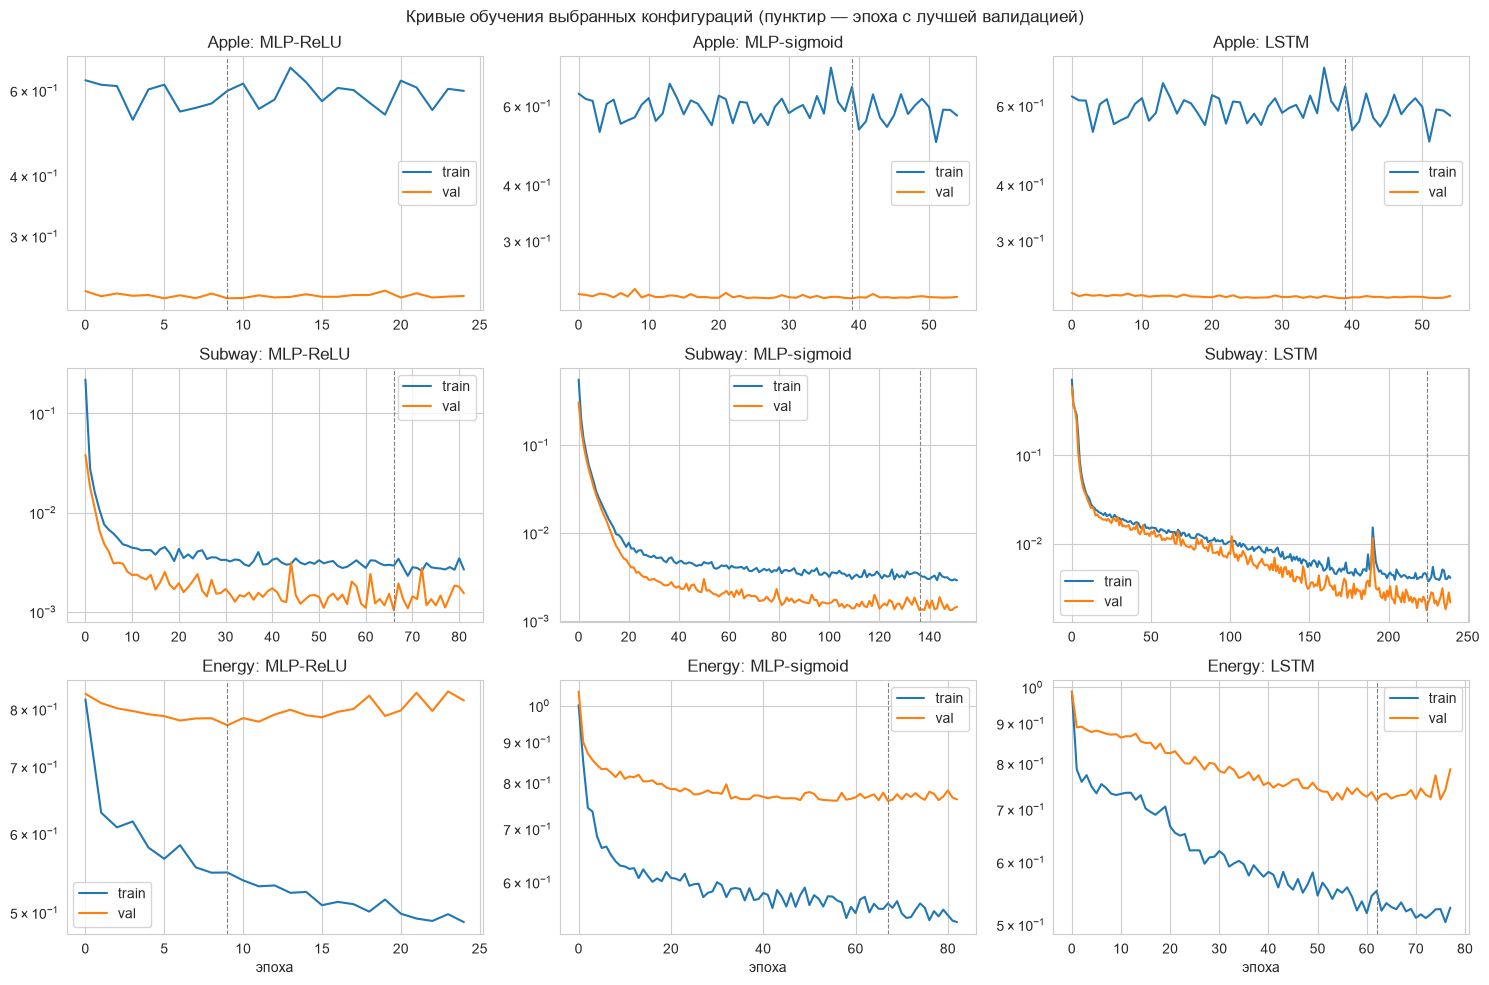

In [21]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for i, name in enumerate(SERIES):
    for j, kind in enumerate(NN_MODELS):
        h = curves[(name, kind)]
        ax = axes[i, j]
        ax.plot(h[:, 0], label="train"); ax.plot(h[:, 1], label="val")
        ax.axvline(np.argmin(h[:, 1]), color="gray", ls="--", lw=0.8)
        ax.set_yscale("log"); ax.set_title(f"{name}: {kind}"); ax.legend()
        if i == 2: ax.set_xlabel("эпоха")
plt.suptitle("Кривые обучения выбранных конфигураций (пунктир — эпоха с лучшей валидацией)")
plt.tight_layout(); plt.show()

**Подбор гиперпараметров.**
* Энергия. Валидационная MSE 0.72-0.78 в нормированных единицах намного выше, чем у метро. Изменения нагрузки за 14 суток определяются погодой, которой нет в истории ряда. Разница между конфигурациями в пределах 8%, лучшая LSTM (n = 64, lr = 1e-3, 0.719). Перцептрон с ReLU переобучается почти сразу (лучшая эпоха 9 - обучающая ошибка падает, валидационная растет), sigmoid-перцептрон обучается медленнее и выходит на плато
* Метро. Почти все конфигурации дают близкую валидационную MSE (0.0010-0.0026), кроме LSTM с n = 32, lr = 1e-3 (0.017). За отведенные эпохи она не успела обучиться. У sigmoid-перцептрона с n = 32 лучшим оказался lr = 3e-3. LSTM обучалась дольше всех (240 эпох), около 190-й эпохи ошибка подскочила, но ограничение градиента не дало обучению разойтись. Валидационная ошибка ниже обучающей, потому что валидация приходится на сентябрь–октябрь, а в обучение входят праздники и летние месяцы с нетипичным профилем
* Apple. Все 12 конфигураций дают val MSE 0.223-0.224, разница на уровне шума. Предсказуемой структуры в изменениях цены нет

## Тестирование

In [22]:
rows = []
for name, x in SERIES.items():
    z, scale = prep[name]["z"], prep[name]["scale"]
    for kind in NN_MODELS:
        model = nets[(name, kind)]
        t0 = time.perf_counter()
        for k, o in enumerate(ORIGINS[name]):
            yhat = forecast_net(model, z, o, LOOKBACK[name], scale, USE_LOG[name])
            forecasts[(name, kind, k)] = yhat
            for h in HORIZONS:
                rows.append(dict(series=name, model=kind, family="NN", horizon=h, segment=k,
                                 MAPE=mape(x[o:o + h], yhat[:h]), MAE=mae(x[o:o + h], yhat[:h])))
        dt = time.perf_counter() - t0
        for t in timing:
            if t["series"] == name and t["model"] == kind:
                t["predict_s"] = dt
                t["total_s"] = t["train_s"] + dt
results = pd.concat([results_ar, pd.DataFrame(rows)], ignore_index=True)
results.to_csv(RESULTS_DIR / "lab4_results.csv", index=False)

ALL_MODELS = list(AR_MODELS) + NN_MODELS
json.dump({f"{s}|{m}": dict(hidden=int(t["hidden"]), lr=float(t["lr"]))
           for t in timing if "hidden" in t for s, m in [(t["series"], t["model"])]},
          open(RESULTS_DIR / "lab4_best_hparams.json", "w"), indent=1)

# Сводная таблица

Медиана MAPE (%) по 10 блокам. Зеленым выделена лучшая модель в строке

In [23]:
summary = results.groupby(["series", "horizon", "model"])["MAPE"].agg(median="median", mean="mean").round(2)
table = summary["median"].unstack("model").reindex(columns=ALL_MODELS)
display(table.style.format("{:.2f}", na_rep="—").highlight_min(axis=1, color="#c6efce")
        .set_caption("Медиана MAPE, %"))

In [24]:
mean_table = summary["mean"].unstack("model").reindex(columns=ALL_MODELS)
display(mean_table.style.format("{:.2f}", na_rep="—").highlight_min(axis=1, color="#c6efce")
        .set_caption("Среднее MAPE, %"))

In [25]:
mae_table = results.groupby(["series", "horizon", "model"])["MAE"].median().unstack("model").reindex(columns=ALL_MODELS)
display(mae_table.style.format("{:.4g}", na_rep="—").highlight_min(axis=1, color="#c6efce")
        .set_caption("Медиана MAE (в единицах ряда)"))

# Boxplot MAPE

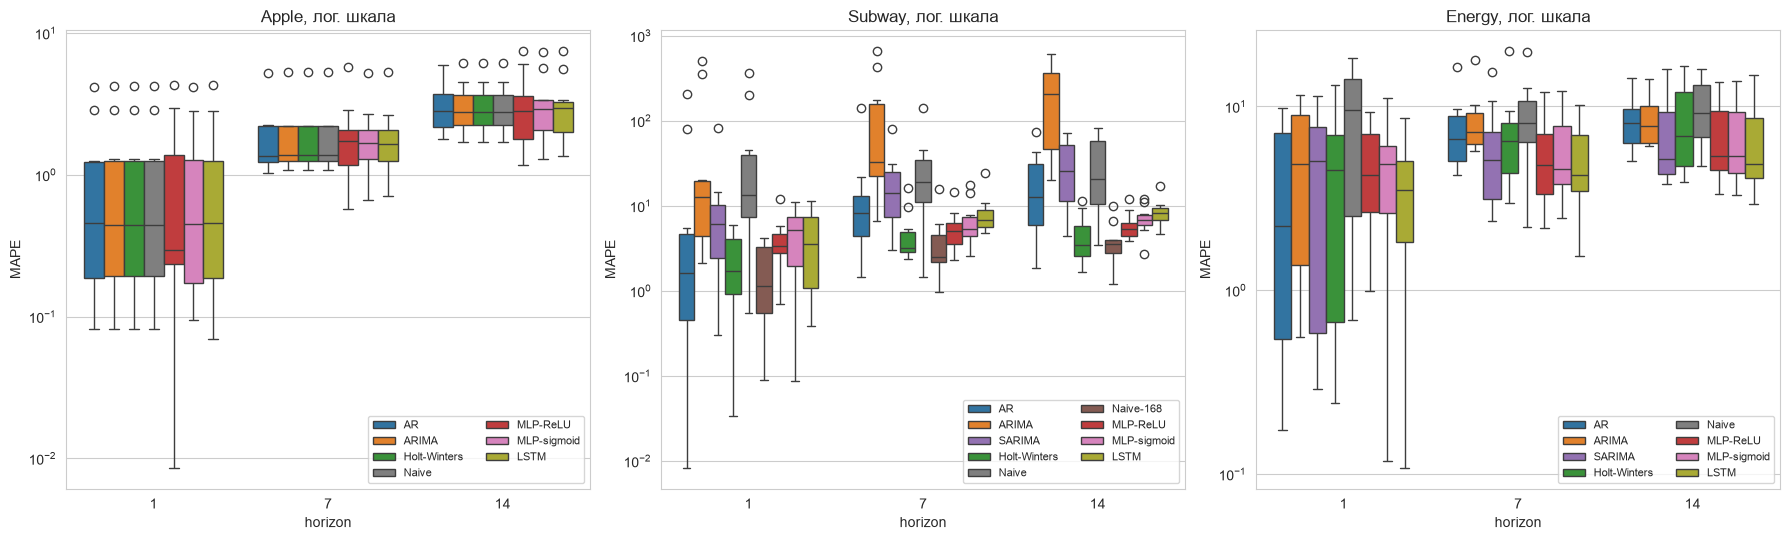

In [26]:
pal = dict(zip(ALL_MODELS, ["tab:blue", "tab:orange", "tab:purple", "tab:green", "tab:gray", "tab:brown",
                            "tab:red", "tab:pink", "tab:olive"]))
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, name in zip(axes, SERIES):
    d = results[results.series == name]
    order = [m for m in ALL_MODELS if m in d.model.unique()]
    sns.boxplot(data=d, x="horizon", y="MAPE", hue="model", hue_order=order, palette=pal, ax=ax)
    ax.set_yscale("log")
    ax.set_title(f"{name}, лог. шкала")
    ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Энергия.**

* На 1 сутки по медиане лучшая AR(9) (2.23%): завтрашняя нагрузка близка к сегодняшней с поправкой на день недели, и линейная модель это хорошо описывает. По среднему MAPE лучшая LSTM (3.7% против 3.9% у AR), то есть AR в типичном блоке точнее, но в отдельных блоках ошибается сильнее. Копия прошлой недели 9.6%.
* На 7 и 14 сутках лучшая модель LSTM и по медиане (4.3 / 4.9%), и по среднему (5.2 / 6.7%). Перцептроны 4.6-5.4 %. Из AR-моделей ближе всех SARIMA (5.1 / 5.2%): на 7 сутках она уступает перцептронам, а на 14 сутках даже немного их обходит (5.2 против 5.4%). Хольт–Винтерс, ARIMA и AR хуже (6.5-8.1 %), копия прошлой недели хуже всех (8.2 / 9.2%)

Возможная причина. Тестовая зона - переход от весеннего минимума к летнему пику. Сети обучены на 16 годах и много раз видели такой переход, а AR-модели переобучаются на последних двух годах и линейны

**Метро.** Лучшими остаются копия прошлой недели Naive-168 (медиана 1.2 / 2.5 / 3.6%) и Хольт–Винтерс с m = 168 (1.7 / 3.2 / 3.5%). Лучшая нейросеть перцептрон с ReLU (3.4 / 5.1 / 5.4%), за ним sigmoid-перцептрон (5.2 / 5.3 / 6.8%) и LSTM (3.5 / 6.9 / 8.2%). На горизонтах 7 и 14 все нейросети заметно лучше AR(170) (8.2 / 12.8%), SARIMA, ARIMA и суточного наивного прогноза, но хуже недельных моделей. Окно L = 168 содержит прошлую неделю, так что сеть могла бы ее просто копировать, но она обучена на всем годе с праздниками и выдает усредненный профиль. У нейросетей нет катастрофических выбросов, как у AR и ARIMA (до сотен процентов в ночные часы), прогноз отклонения от последнего значения в логарифмах не уходит в отрицательную область

**Apple.** Все модели практически равны наивному прогнозу: медиана 0.3–0.5 / 1.4–1.7 / 2.8–3.0%, среднее 1.1 / 1.9–2.0 / 3.2–3.3%, ящики полностью перекрываются. Нейросети на 7 сутках по медиане даже немного хуже наивного прогноза (1.7 против 1.4%), но разница в пределах разброса между блоками

# Время расчета

* AR-модели: суммарное время обучения и прогноза на 10 блоках (модель переобучается перед каждым блоком).
* Нейросети: время обучения выбранной конфигурации (один раз), время прогноза 10 блоков, а также время всего подбора по сетке из 4 конфигураций.

In [27]:
tim = pd.DataFrame(timing).set_index(["series", "model"])
tim = tim[["train_s", "predict_s", "total_s", "grid_s"]].rename(columns={
    "train_s": "обучение, с", "predict_s": "прогноз 10 блоков, с", "total_s": "итого, с",
    "grid_s": "подбор по сетке, с"})
display(tim.style.format("{:.3f}", na_rep="—").set_caption("Время расчета, секунды"))

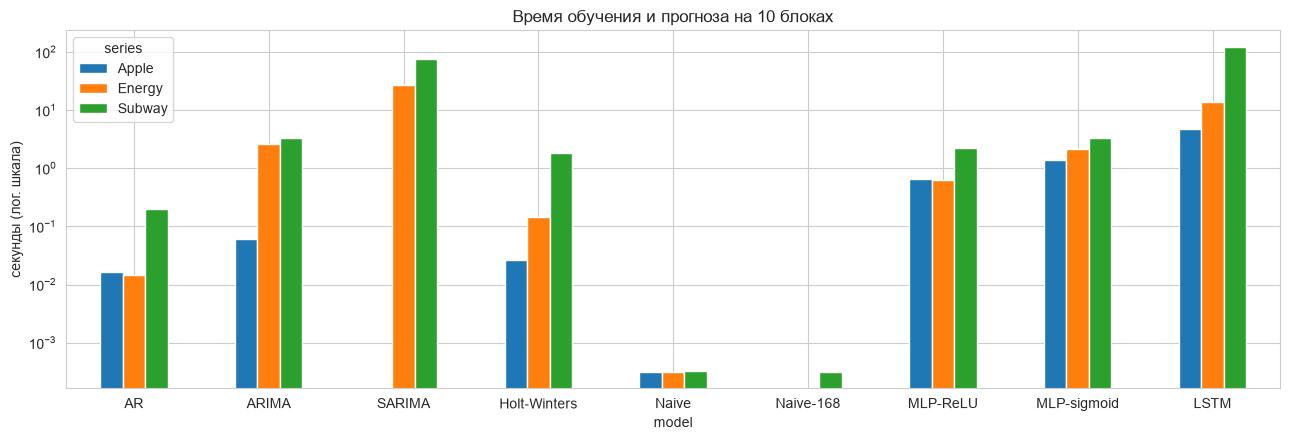

In [28]:
fig, ax = plt.subplots(figsize=(13, 4.5))
tp = tim["итого, с"].unstack("series").reindex(ALL_MODELS)
tp.plot.bar(ax=ax, logy=True)
ax.set_ylabel("секунды (лог. шкала)"); ax.set_title("Время обучения и прогноза на 10 блоках")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

* AR-модели переобучаются перед каждым блоком: на 10 блоков от 0.02 с (AR) до 27 с (SARIMA для энергии) и 75 с (SARIMA для метро). У SARIMA время выросло из-за переобучения Нелдером–Мидом в блоках, где не сошелся основной оптимизатор. Наивные прогнозы занимают доли миллисекунды
* Перцептроны обучаются за 0.6–3 секунд. LSTM за 5 с (Apple, L = 20), 14 с (энергия, L = 56) и 123 с (метро, L = 168): последовательность обрабатывается шаг за шагом, и время растет с длиной окна. Подбор по сетке из 4 конфигураций занимает в 2–4 раза больше (до 235 с для LSTM на метро).
* Прогноз обученной сети на 10 блоков занимает 1–16 мс, на три-четыре порядка быстрее переобучения SARIMA. Поэтому, если модель обучается редко, а прогнозов нужно много, нейросеть в работе быстрее
* Для энергии LSTM дает лучшую точность на 7–14 сутках за 14 с обучения - быстрее, чем 10 переобучений SARIMA (27 с). Для метро недельный наивный прогноз за 0 с точнее любой нейросети

# Примеры прогнозов

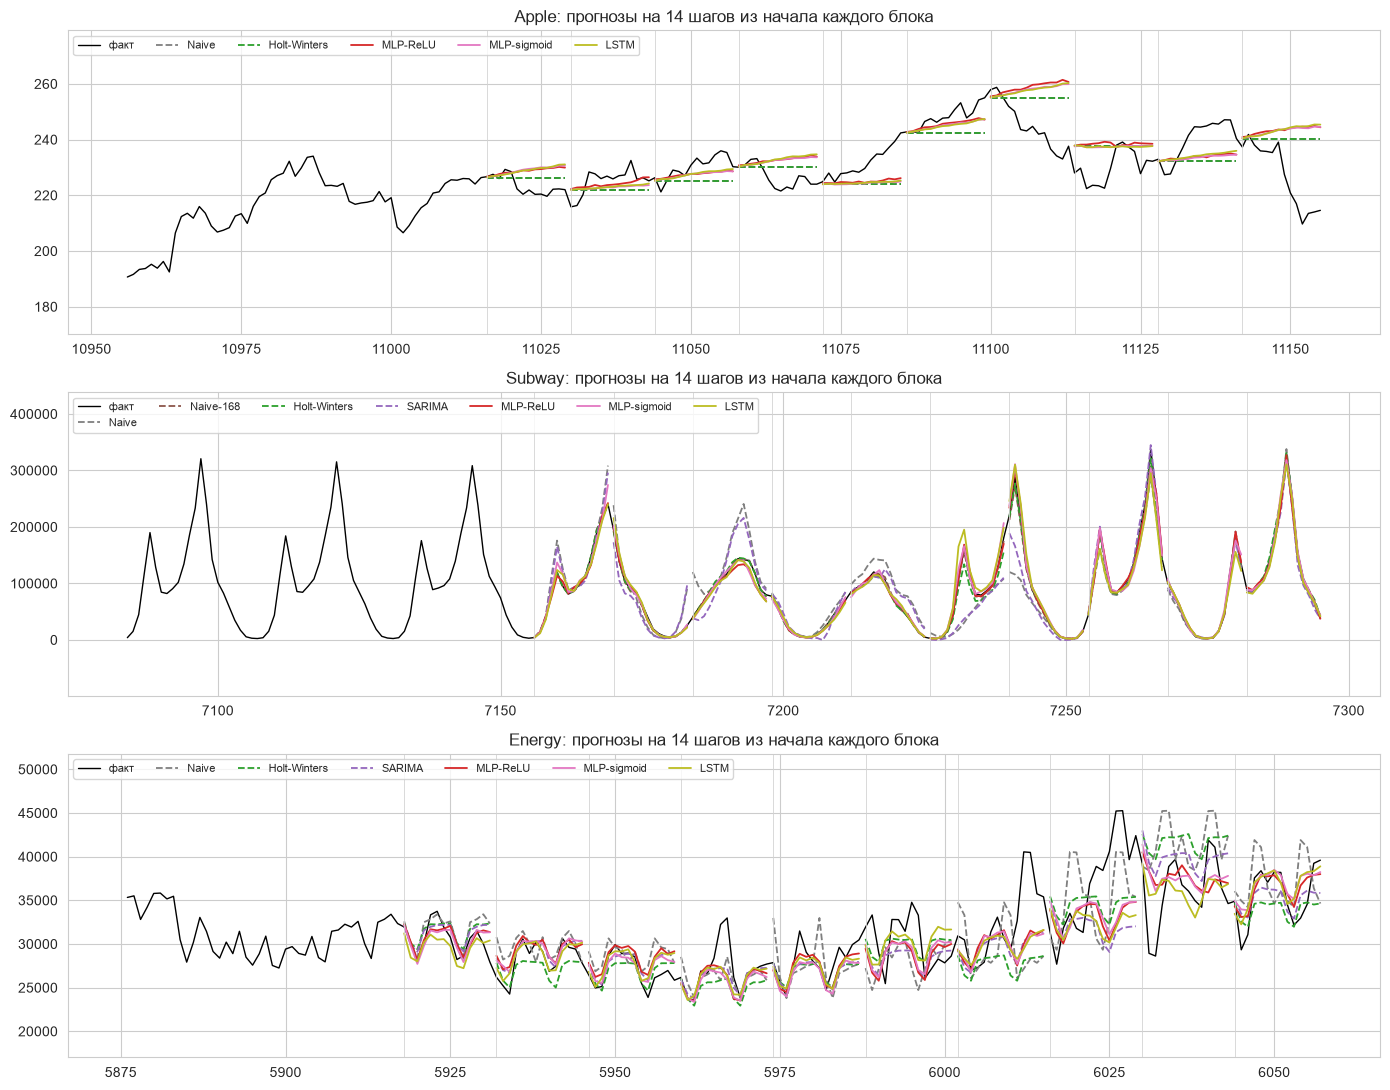

In [29]:
show = ["Naive", "Naive-168", "Holt-Winters", "SARIMA", "MLP-ReLU", "MLP-sigmoid", "LSTM"]
fig, axes = plt.subplots(3, 1, figsize=(14, 11))
for ax, (name, x) in zip(axes, SERIES.items()):
    origins = ORIGINS[name]
    ctx = {"Apple": 60, "Subway": 24 * 3, "Energy": 42}[name]
    shown = origins
    end = shown[-1] + H_MAX
    ax.plot(np.arange(origins[0] - ctx, end), x[origins[0] - ctx:end], color="black", lw=1, label="факт")
    for k, o in enumerate(shown):
        for m in show:
            if (name, m, k) in forecasts:
                ax.plot(np.arange(o, o + H_MAX), forecasts[(name, m, k)], color=pal[m], lw=1.3,
                        ls="--" if m in AR_MODELS else "-", label=m if k == 0 else None)
        ax.axvline(o, color="lightgray", lw=0.6)
    ax.set_title(f"{name}: прогнозы на 14 шагов из начала каждого блока")
    seg = x[origins[0] - ctx:end]
    pad = 0.3 * (seg.max() - seg.min())
    ax.set_ylim(seg.min() - pad, seg.max() + pad)
    ax.legend(ncol=7, fontsize=8)
plt.tight_layout(); plt.show()

Энергия. Копия прошлой недели (Naive) и Хольт–Винтерс переносят на прогноз уровень прошлой недели. Когда погода меняется, они ошибаются сильнее всех: в начале июля жара подняла нагрузку до 45 тыс. МВт, и через неделю эти прогнозы повторили пик, когда жара уже спала. Нейросети и SARIMA дают сглаженный недельный профиль вокруг текущего уровня: пики жары они тоже не предсказывают, но и не переносят их туда, где их нет.

Метро. Все нейросети повторяют суточный профиль и правильно переходят «будни - выходные», так как прошлые выходные есть во входном окне. Ошибаются в основном на высоте пиков. SARIMA с суточным периодом переносит профиль пятницы на субботу (завышает) и воскресенья на понедельник (занижает)

Apple. Прогнозы AR-моделей — горизонтальные линии на уровне последнего значения. Нейросети дают слабый рост, то есть продолжают средний рост цены за историю

**Итоги**

1. Полезность нейросетей зависит от структуры ряда.
* Энергия (недельный цикл плюс годовой, управляемый погодой): на 7–14 сутках лучшая модель LSTM, она обходит все AR-модели. На 1 сутки по медиане лучшая AR(9)
* Метро (устойчивый недельный профиль): лучшая модель получилась простая копия прошлой недели и Хольт–Винтерс с m = 168. Нейросети на третьем месте, но обходят AR(170), SARIMA и ARIMA на горизонтах 7–14 и не дают выбросов
* Случайное блуждание (Apple): все модели сводятся к наивному прогнозу
  
2. Из трех архитектур LSTM лучше на энергии, перцептрон с ReLU на метро. Sigmoid-перцептрон нигде не лучший: ему нужна большая скорость обучения и больше эпох, что согласуется с затуханием градиента сигмоиды
3. Прямой многошаговый прогноз (14 выходов сразу) и прогноз отклонения от последнего значения в логарифмах делают ошибку нейросетей устойчивой. Она медленно растет с горизонтом и не дает выбросов в сотни процентов
4. Обучение нейросети дороже обучения AR-модели (секунды–минуты против долей секунды–десятков секунд), LSTM самая медленная модель. Но прогноз обученной сети занимает миллисекунды